# Spike-Frequency Adaptation

Many neurons fire rapidly at the onset of a sustained stimulus and then slow down. This **spike-frequency adaptation** is commonly produced by a calcium-activated potassium current (an AHP current): each spike admits calcium, calcium gradually activates the AHP conductance, and the growing outward current lengthens successive inter-spike intervals (ISIs).

In [1]:
import brainstate
import brainunit as u
import numpy as np
import matplotlib.pyplot as plt
import braincell
from braincell import mech

## A cell with an AHP current

We combine sodium and delayed-rectifier potassium for spiking, a set of L-, N-, T-, and high-threshold calcium currents as the calcium source, and a calcium-activated potassium current (`AHP_De1994`), which the cell binds to both the potassium and the calcium ion.

In [2]:
def AdaptingCell(size, solver='ind_exp_euler'):
    """A thalamic-relay-style point neuron with a Ca-activated K (AHP) current."""
    cell = braincell.Cell.point(size, V_init=-65. * u.mV, V_th=20. * u.mV, solver=solver)
    cell.paint(
        mech.Ion('SodiumFixed', E=50. * u.mV),
        mech.Channel('Na_Ba2002', V_sh=-30 * u.mV),
        mech.Ion('PotassiumFixed', E=-90. * u.mV),
        mech.Channel('K_Leak', g_max=0.01 * (u.mS / u.cm ** 2)),
        mech.Channel('KDR_Ba2002', V_sh=-30. * u.mV, q10=2.0, temp=u.celsius2kelvin(16.)),
        mech.Ion('CalciumDetailed', C_rest=5e-5 * u.mM, tau=10. * u.ms, d=0.5 * u.um),
        mech.Channel('CaL_IS2008', g_max=0.5 * (u.mS / u.cm ** 2)),
        mech.Channel('CaN_IS2008', g_max=0.5 * (u.mS / u.cm ** 2)),
        mech.Channel('CaT_HM1992', g_max=2.1 * (u.mS / u.cm ** 2)),
        mech.Channel('CaT_HM1992_Shifted25', g_max=3.0 * (u.mS / u.cm ** 2)),
        mech.Channel('AHP_De1994', g_max=0.3 * (u.mS / u.cm ** 2)),
        mech.Channel('IL', g_max=0.0075 * (u.mS / u.cm ** 2), E=-70 * u.mV),
    )
    return cell

## Drive with a sustained current

A constant 2 uA/cm^2 injection evokes repetitive firing. We record the spike times to measure how the ISIs evolve.

In [3]:
cell = AdaptingCell(1)
cell.init_state()

I = 2. * u.uA / u.cm ** 2

def step(t):
    with brainstate.environ.context(t=t):
        cell.update(I)
    return cell.V.value, cell.spike.value

with brainstate.environ.context(dt=0.01 * u.ms):
    times = u.math.arange(0. * u.ms, 500. * u.ms, brainstate.environ.get_dt())
    vs, spikes = brainstate.transform.for_loop(step, times)

spike_times = np.asarray(times[u.math.squeeze(spikes) > 0] / u.ms)
isi = np.diff(spike_times)
print('number of spikes:', spike_times.size)
print('first ISIs (ms):', np.round(isi[:6], 2).tolist())

number of spikes: 27
first ISIs (ms): [9.180000305175781, 6.610000133514404, 9.869999885559082, 14.229999542236328, 17.989999771118164, 19.690000534057617]


## Visualize the adaptation

The voltage trace (top) opens with a short burst: at -65 mV the T-type calcium current is not inactivated, so the first spikes come fast. Firing then slows, and after the burst the ISI sequence (bottom) lengthens steadily, from about 7 ms to 20 ms — the quantitative signature of adaptation.

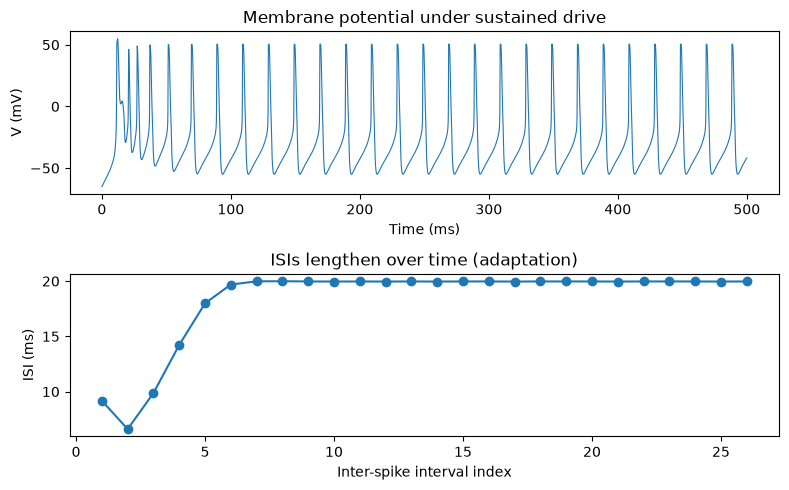

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(8, 5))
axs[0].plot(times / u.ms, u.math.squeeze(vs) / u.mV, linewidth=0.8)
axs[0].set_xlabel('Time (ms)'); axs[0].set_ylabel('V (mV)')
axs[0].set_title('Membrane potential under sustained drive')
axs[1].plot(np.arange(1, isi.size + 1), isi, 'o-')
axs[1].set_xlabel('Inter-spike interval index'); axs[1].set_ylabel('ISI (ms)')
axs[1].set_title('ISIs lengthen over time (adaptation)')
plt.tight_layout(); plt.show()